In [8]:
# imports
%matplotlib widget
import numpy as np
import scipy.integrate as spintg
import scipy.interpolate as spintp
from dataclasses import dataclass
from enum import IntEnum
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

from utils import *
from plots import *
import guards, resets, drawing
from hybrid_plots import plot_hybrid
from system_control import open_loop_control
from hybrid_system import simulate_hybrid_system

In [9]:
p = Params()

### Q1.1) Kinematics
From the given problem, the kinematics derived are the following:
$$
\begin{aligned}
x(\theta_l,\theta_r) &= \frac{r_m(\theta_l+\theta_r) - d_y}{2} \\
y(\theta_l,\theta_r) &= \frac{r_m(\theta_l-\theta_r) + d_y}{2} \\
\dot{x}(\dot\theta_l,\dot\theta_r) &= \frac{r_m}{2}\left(\dot\theta_l+\dot\theta_r\right) \\
\dot{y}(\dot\theta_l,\dot\theta_r) &= \frac{r_m}{2}\left(\dot\theta_l-\dot\theta_r\right)
\end{aligned}
$$

I considered a model in which the tool head is a point mass, and by checking the tool head's position at a hypothetical $\theta_l = 0$ and $\theta_r = 0$ and using intuition I was able to determine the effects of rotation of the xy position of the tool head. Notice that I also used $d_x$ and $d_y$ in my formulation to stay as close as possible to the physical system. Below you can find a (very) simple interactive graph that shows how our tool head moves if only one of the motors is active at a time.

In [10]:
def calculate_position(theta_l, theta_r, d_x, d_y, r_m):
    x = ((r_m * (theta_l + theta_r))) / 2
    y = ((r_m * (theta_l - theta_r) + d_y)) / 2

    return x, y

interactive(children=(FloatSlider(value=20.0, description='theta_l', max=40.0), FloatSlider(value=20.0, descri…

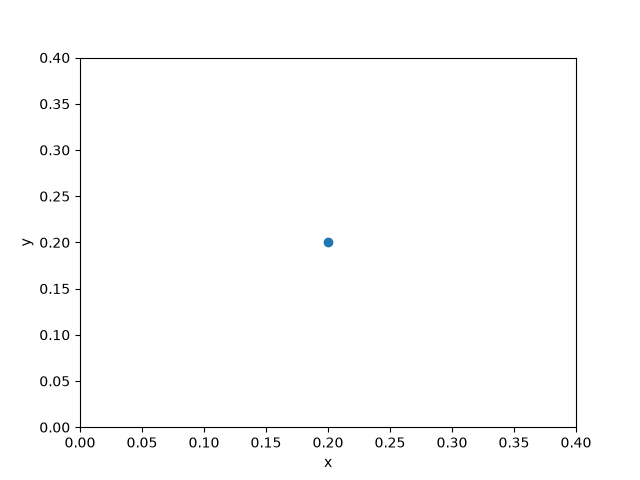

In [11]:
# Here I define my static variables. They can be changed but are chosen for convenience in plotting
# I am trying to keep the plots as general and customizable as possible!
theta_l_init = 20.0
theta_r_init = 20.0

x, y = calculate_position(theta_l_init, theta_r_init, p.dx, p.dx, p.r_m)

fig, ax = plt.subplots()

ax.set(xlim=(0, p.dx), ylim=(0, p.dx))
ax.set_xlabel("x")
ax.set_ylabel("y")

plot = ax.scatter(x, y) # Create INITIAL scatter plot

@widgets.interact(
    theta_l=widgets.FloatSlider(min=0.0, max=40.0, value=theta_l_init, step=0.1),
    theta_r=widgets.FloatSlider(min=0.0, max=40.0, value=theta_r_init, step=0.1)
)
def update_position(theta_l, theta_r):
    
    x, y = calculate_position(theta_l, theta_r, p.dx, p.dy, p.r_m)

    print(x, y)

    plot.set_offsets([[x, y]])

    fig.canvas.draw_idle()

### Q1.2) Dynamics
The dynamics were more complex, and involved switching between the electrical, rotational mechanical, and lienar mechanical domains. My approach was to derive the motor torque ($\tau_l$ and $\tau_r$) from the input voltage $u_l$, and consider the torque as an input force in the Euler-Lagrange equation.
## Electrical Domain

![Electrical Domain](images/electrical_domain.png)

The equations for the electrical domain are as follows:
$$
\begin{aligned}
u_l &= v_{m,l} + R_m i_l + L_m \frac{di_l}{dt} \\
\tau_l &= K_M i_l \\
\dot\theta_l &= \frac{1}{K_m} v_{m,l} = \frac{1}{K_M}\left(u_l - R_m i_l - L_m \frac{di_l}{dt}\right)
\end{aligned}
$$

Rewritten in state-space form in the case of the current's derivative:

$$
\frac{di_l}{dt} = -\frac{K_M}{L_m}\dot\theta_l - \frac{R_m}{L_m} i_l + \frac{1}{L_m} u_l
$$

Naturally, the equations for the right-side motor will be the same

## Mechanical Domain

Here it is viable to use the Euler-Lagrange equations to derive the dynamics of this part of our system:

# Lagrangian

$$
\begin{aligned}
K &= \frac{1}{2} m\left(\dot x^2 + \dot y^2\right) + \frac{1}{2} J_m\left(\dot\theta_l^2 + \dot\theta_r^2\right) \\
  &= \frac{1}{2} m \frac{r_m^2}{4}\left[(\dot\theta_l+\dot\theta_r)^2 + (\dot\theta_l-\dot\theta_r)^2\right] + \frac{1}{2} J_m\left(\dot\theta_l^2 + \dot\theta_r^2\right) \\
  &= \frac{1}{2}\left(\frac{r_m^2 m}{2} + J_m\right)\left(\dot\theta_l^2 + \dot\theta_r^2\right) \\[6pt]
\mathcal{L} &= K - P = K = \frac{1}{2}\left(\frac{r_m^2 m}{2} + J_m\right)\left(\dot\theta_l^2 + \dot\theta_r^2\right),
\qquad \boldsymbol{q} = \begin{bmatrix}\theta_l \\ \theta_r\end{bmatrix}
\end{aligned}
$$

# Dissipation
For the dissipation, I am considering a linear friction for the linear bearings and an rotational dampening effect $\mu_r$ for each bearing. The key insight for this part was that not all bearings rotate at the same speed! The bearings not attached to the moving crossbars rotate with $\frac{r_m}{r_b}\theta$, while the others (the black ones) only "saw" the x axis movement of the tool head for their rotation, since the belt only moves in that direction from their point of view. This means that they require a different equation for the friction they encounter (bottom center):



$$
\begin{aligned}
D ={}& \mu_{l,y}\frac{r_m^2}{4}\left(\dot\theta_l-\dot\theta_r\right)^2
     + \mu_{l,x}\frac{r_m^2}{4}\left(\dot\theta_l+\dot\theta_r\right)^2 \\
   &+ 2\cdot\frac{1}{2}\mu_r\left(\frac{r_m}{r_b}\dot\theta_l\right)^2
     + 4\cdot\frac{1}{2}\mu_r\left(\frac{r_m}{2r_b}\left(\dot\theta_l+\dot\theta_r\right)\right)^2
     + 2\cdot\frac{1}{2}\mu_r\left(\frac{r_m}{r_b}\dot\theta_r\right)^2
\end{aligned}
$$

# Euler-Lagrange Equation
Putting these two terms together along with my input forces $\tau_l$ and $tau_r$ brings me:

$$
\frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{\boldsymbol q}}\right)
- \frac{\partial \mathcal{L}}{\partial \boldsymbol q}
= - \frac{\partial D}{\partial \dot{\boldsymbol q}}
+ \boldsymbol\tau,
\qquad
\boldsymbol\tau = \begin{bmatrix}\tau_l \\ \tau_r\end{bmatrix} = K_M\begin{bmatrix} i_l \\ i_r\end{bmatrix}
$$

With:

$$
\frac{d}{dt}\left(\frac{\partial \mathcal{L}}{\partial \dot{\boldsymbol q}}\right)
=
\begin{bmatrix}
\left(\frac{r_m^2 m}{2} + J_m\right)\ddot\theta_l \\
\left(\frac{r_m^2 m}{2} + J_m\right)\ddot\theta_r
\end{bmatrix}
$$

And:

$$
\frac{\partial D}{\partial \dot{\boldsymbol q}} =
\begin{bmatrix}
2\mu_r\frac{r_m^2}{r_b^2}\dot\theta_l + \mu_r\frac{r_m^2}{r_b^2}\left(\dot\theta_l+\dot\theta_r\right)
+ \frac{\mu_{l,y}}{2} r_m^2\left(\dot\theta_l-\dot\theta_r\right) + \frac{\mu_{l,x}}{2} r_m^2\left(\dot\theta_l+\dot\theta_r\right) \\[4pt]
2\mu_r\frac{r_m^2}{r_b^2}\dot\theta_r + \mu_r\frac{r_m^2}{r_b^2}\left(\dot\theta_l+\dot\theta_r\right)
- \frac{\mu_{l,y}}{2} r_m^2\left(\dot\theta_l-\dot\theta_r\right) + \frac{\mu_{l,x}}{2} r_m^2\left(\dot\theta_l+\dot\theta_r\right)
\end{bmatrix}
=
\begin{bmatrix}
(3F_1+F_2)\dot\theta_l + (F_1+F_3)\dot\theta_r \\
(F_1+F_3)\dot\theta_l + (3F_1+F_2)\dot\theta_r
\end{bmatrix}
$$

$$
F_1 = \mu_r\frac{r_m^2}{r_b^2},
\qquad
F_2 = \frac{r_m^2}{2}\left(\mu_{l,x}+\mu_{l,y}\right),
\qquad
F_3 = \frac{r_m^2}{2}\left(\mu_{l,x}-\mu_{l,y}\right)
$$

By putting everything together, I can get:

$$
\frac{d}{dt}
\begin{bmatrix} \theta_l \\ \dot\theta_l \\ i_l \\ \theta_r \\ \dot\theta_r \\ i_r \end{bmatrix}
=
\begin{bmatrix}
0 & 1 & 0 & 0 & 0 & 0 \\
0 & \frac{-2(3F_1+F_2)}{r_m^2 m + 2 J_m} & \frac{2 K_M}{r_m^2 m + 2 J_m} & 0 & \frac{-2(F_1+F_3)}{r_m^2 m + 2 J_m} & 0 \\
0 & -\frac{K_M}{L_m} & -\frac{R_m}{L_m} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 \\
0 & \frac{-2(F_1+F_3)}{r_m^2 m + 2 J_m} & 0 & 0 & \frac{-2(3F_1+F_2)}{r_m^2 m + 2 J_m} & \frac{2 K_M}{r_m^2 m + 2 J_m} \\
0 & 0 & 0 & 0 & -\frac{K_M}{L_m} & -\frac{R_m}{L_m}
\end{bmatrix}
\begin{bmatrix} \theta_l \\ \dot\theta_l \\ i_l \\ \theta_r \\ \dot\theta_r \\ i_r \end{bmatrix}
+
\begin{bmatrix}
0 & 0 \\ 0 & 0 \\ \frac{1}{L_m} & 0 \\ 0 & 0 \\ 0 & 0 \\ 0 & \frac{1}{L_m}
\end{bmatrix}
\begin{bmatrix} u_l \\ u_r \end{bmatrix}
$$

### Q1.3) Decoupling

In order to decouple the x and y directions I can apply a simple transformation to the state of my model: 
sum $\theta_l$ and $\theta_y$ and multiply by $\frac{r_m}{2}$ for $x$, subtract $\theta_l$ and $\theta_y$ and multiply by $\frac{r_m}{2}$ for $y$. This can be applied at a matrix level as well, as it describes linear (differential) equations!
I decided to also derive an "x current" $i_x$ and "y current" $i_y$ with this transformation, losing some physical meaning in order to achieve the decoupling. This is already the case for $u_x$ and $u_y$ anyways.

$$
\begin{aligned}
\dot{x}(\dot\theta_l,\dot\theta_r) &= \frac{r_m}{2}\left(\dot\theta_l+\dot\theta_r\right) \\
\dot{y}(\dot\theta_l,\dot\theta_r) &= \frac{r_m}{2}\left(\dot\theta_l-\dot\theta_r\right)
\end{aligned}
$$


$$
C_m = \frac{r_m}{r_m^2 m + 2J_m}
$$

$$
\frac{d}{dt}
\begin{bmatrix} x \\ \dot x \\ i_x \\ y \\ \dot y \\ i_y \end{bmatrix}
=
\underbrace{\begin{bmatrix}
0 & 1 & 0 & 0 & 0 & 0 \\
0 & -\frac{2C_m}{r_m}(4F_1+F_2+F_3) & K_m C_m & 0 & 0 & 0 \\
0 & -\frac{2K_m}{r_m L_m} & -\frac{R_m}{L_m} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 0 & -\frac{2C_m}{r_m}(2F_1+F_2-F_3) & K_m C_m \\
0 & 0 & 0 & 0 & -\frac{2K_m}{r_m L_m} & -\frac{R_m}{L_m}
\end{bmatrix}}_{A}
\begin{bmatrix} x \\ \dot x \\ i_x \\ y \\ \dot y \\ i_y \end{bmatrix}
+
\underbrace{\begin{bmatrix}
0 & 0 \\ 0 & 0 \\ \frac{1}{L_m} & 0 \\ 0 & 0 \\ 0 & 0 \\ 0 & \frac{1}{L_m}
\end{bmatrix}}_{B}
\begin{bmatrix} u_x \\ u_y \end{bmatrix}
$$

Below you can find the derived matrices in code.

In [12]:
A, B, C, CAAB, CAAA = get_sys_matrices(p)

### Q1.4) Drawing Shapes

In order to draw an arbitrary shape (in the case of this code an ellipse), I need to derive the input $u$ that can give me a certain desired behavior of the system. 

$$
\dot{\boldsymbol x} = A\boldsymbol x + B\boldsymbol u
\quad\Rightarrow\quad
\boldsymbol u = B^{-1}\left(\dot{\boldsymbol x} - A\boldsymbol x\right)
$$

Since I only care about the position of my tool head, I decided to encode this desire in an output function p:

$$
\boldsymbol p = C\boldsymbol x =
\begin{bmatrix} x \\ y \end{bmatrix}
=
\begin{bmatrix}
1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1 & 0 & 0
\end{bmatrix}
\boldsymbol x
$$

$$
\begin{aligned}
\dot{\boldsymbol p} &= CA\boldsymbol x + \underbrace{CB}_{=\,0}\boldsymbol u
&&\Rightarrow\ \boldsymbol u = (CB)^{-1}\left(\dot{\boldsymbol p} - CA\boldsymbol x\right) \ \text{ is not possible} \\[4pt]
\ddot{\boldsymbol p} &= CA^2\boldsymbol x + \underbrace{CAB}_{=\,0}\boldsymbol u + \underbrace{CB}_{=\,0}\dot{\boldsymbol u}
&&\Rightarrow\ \text{the input does not appear yet} \\[4pt]
\dddot{\boldsymbol p} &= CA^3\boldsymbol x + CA^2B\,\boldsymbol u
&&\Rightarrow\ \text{the input appears in the jerk!}
\end{aligned}
$$

Notice that I can invert this relationship to derive u only when I consider the jerk of my positional coordinates. sharp corners in my shape will cause very high acceleration and jerk values that can cause numerical problems when calculating the inputs required.

$$
\boldsymbol u = \left(CA^2B\right)^{-1}\left(\dddot{\boldsymbol y} - CA^3\boldsymbol x\right)
\qquad
$$

One problem I encountered was that, even though I only wanted to specify the position and velocity of the tool head, I also needed to plug in a desired current trajectory. In reality, I found that this problem wasn't very important, as the current could be linked to position through the first and second derivatives:

$$
\begin{aligned}
\frac{di_x}{dt} &= -\frac{2K_m}{r_m L_m}\dot x - \frac{R_m}{L_m} i_x + \frac{1}{L_m} u_x \\[4pt]
\ddot x &= K_m C_m\, i_x - \frac{2C_m}{r_m}\left(4F_1+F_2+F_3\right)\dot x \\[4pt]
\Rightarrow\ i_x &= \frac{\ddot x}{K_m C_m} + \frac{2}{K_m r_m}\left(4F_1+F_2+F_3\right)\dot x
\end{aligned}
$$

In [19]:
# Time to see if it works!

# My desired trajectory, an ellipse (or generic lissajous curbe)
y = drawing.lissajous(0.2, 0.3, 1, np.pi / 2, 0, np.pi * 2)

t = np.linspace(0, 
                np.pi * 2, #p.t_fin,
                2000) # timepoints

u, x = open_loop_control(y, A, B, C, CAAB, CAAA, p)
u = jax.jit(u)

x0 = x(0.0)

# ODE solver needs a function that can return a value for any time, 
# even not belonging of my linspace t

def f_printer(state, u):
    return A @ state + B @ u

solution = spintg.solve_ivp(lambda t, s: f_printer(s, np.asarray(u(t))),
    (0, p.t_fin), x0, t_eval=t, method='LSODA'
)

y_calculated = C @ solution.y # This is my trajectory

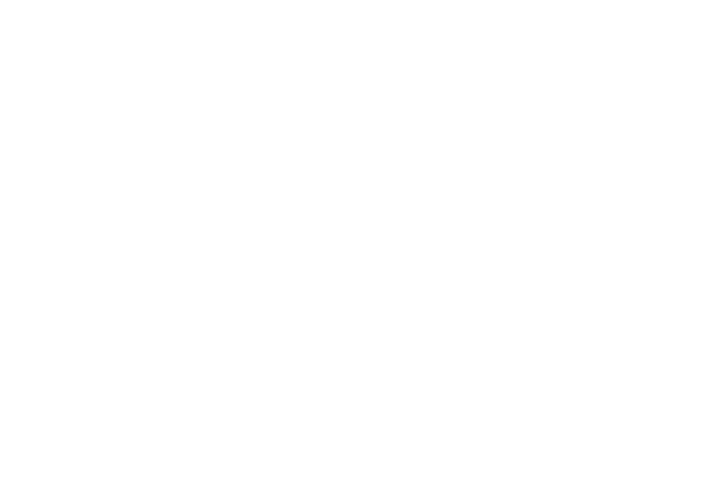

In [20]:
u_arr = np.asarray(jax.vmap(u)(t)).T # .T == Transpose and vmap creates y(t) at index t for every t in my span
y_arr = np.asarray(jax.vmap(y)(t)).T

an = plot_q14(u_arr, y_arr, y_calculated, t) # The figure may not show up due to an unknown problem (I spent an hour trying to fix it).
# In case it does not, try to resize the figure inside the cell output. This should make it render (at least for me)

### Q1.5) Nozzle Temperature

![Nozzle](images/nozzle_circuit.png)

After looking at the circuit, I can see that there will be three state variables: The current passing through the inductor $i_l$, the voltage across the capcitor $v_c$ and the nozzle temperature.
$$
\boldsymbol x_n = \begin{bmatrix} i_n \\ v_c \\ T_n \end{bmatrix}
$$


I am assuming an unchanging external temperature and that all the heat dissipated by the resistor goes into heating the nozzle. With these conditions set, I derived:

# Electrical Domain
$$
\begin{aligned}
L_n \frac{di_n}{dt} &= u_n + v_c \\[4pt]
R_n\left(i_n - C_n \dot v_c\right) &= v_c
\quad\Rightarrow\quad
\dot v_c = -\frac{1}{R_n C_n} v_c + \frac{1}{C_n} i_n
\end{aligned}
$$

# Thermal Domain
The tricky part here was determining what the temperature derivative would be. It is in fact influenced by the resistor through the heat flow it generated $W_{\text{res}}$ and by the external temperature through the thermal resistance $R_{t,n}$
$$
\begin{aligned}
W_{\text{res}} &= \frac{v_c^2}{R_n} \\[4pt]
C_{t,n}\dot T_n &= W_{\text{res}} + \frac{1}{R_{t,n}}\left(T_e - T_n\right)
\quad\Rightarrow\quad
\dot T_n = \frac{1}{C_{t,n}}\left(\frac{v_c^2}{R_n} + \frac{T_e - T_n}{R_{t,n}}\right)
\end{aligned}
$$

# Final Result

Finally, I can express these relations in state-space form:

$$
\dot{\boldsymbol x}_n = f_n(\boldsymbol x_n, u_n) =
\begin{bmatrix}
\frac{1}{L_n} v_c + \frac{1}{L_n} u_n \\[4pt]
\frac{1}{C_n} i_n - \frac{1}{R_n C_n} v_c \\[4pt]
\frac{v_c^2}{C_{t,n} R_n} + \frac{T_e - T_n}{R_{t,n} C_{t,n}}
\end{bmatrix}
$$

In [15]:
def f_nozzle(state, u):

    i_n, v_c, T_n = state

    dx = [
        (1/p.L_n) * (u - v_c),
        (1/p.C_n)*(i_n - (1/p.R_n) * v_c),
        (1/p.C_t_n)*((1/p.R_n) * v_c**2 + (1/p.R_t_n) * (p.T_env - T_n))
    ]

    return dx

###Q1.6) Heat Flow PDE

If I model the filament as having a square cross-section, it follows that one fourth of the surface area of the filament is in contact with the plate underneath with $T_p$, while the rest of its surface is exposed to the environment $T_e$.

# Heat Flux
To represent the internal heat flow along the filament, I use the equation:
$$
\phi_f = -k_f \nabla T_f(x,t)
$$

Where $\phi_f$  [$\frac{W}{m^2}$] is the heat flow density, $k_f$ [$\frac{W}{m K}$] is the thermal conductivity, and $T_f(x, t)$ is the temperature in Kelvin of the filament in position $x$ at time $t$.
# Sources/Sinks
Interaction with the plate and air can be described as a distributed heat flow $q_f$  [$\frac{W}{m^3}$]: 
$$
q_f = \frac{1}{a^2}\left[\frac{3}{4} G_{f,\text{env}}\left(T_e - T_f\right) + \frac{1}{4} G_{f,\text{plate}}\left(T_p - T_f\right)\right]
$$

Where $G_{f,\text{env}}$ and $G_{f,\text{plate}}$ are conductances per unit length of the filament: [$\frac{W}{m K}$]. These values depend on the material and its thickness. Notice how the geometry of the surfaces the filament is in contact with is encoded in the $\frac{3}{4}$ and $\frac{1}{4}$ multipliers

# Balance Equation and Energy Density

Finally, I can use the balance equation for the internal energy density and relate the internal energy density as a function of temperature:

$$
\frac{\partial u}{\partial t} = -\nabla\cdot\phi_f + q_f,
\qquad
u(x,t) = \rho_f c_f T_f(x,t)
$$

Where $\rho_f$ is the volumetric density [$\frac{Kg}{m^3}$] of the filament and $c_f$ is its specific heat capacity [$\frac{J}{Kg \dot K}$]

# PDE
If I put everything together, I can finally find a PDE describing the temperature in space and time
$$
\rho_f c_f \frac{\partial T_f}{\partial t} - k_f \nabla^2 T_f
- \frac{1}{a^2}\left[\frac{3}{4} G_{f,\text{env}}\left(T_e - T_f\right) + \frac{1}{4} G_{f,\text{plate}}\left(T_p - T_f\right)\right] = 0,
\qquad 0 \le x \le \ell(t)
$$

In order to solve this, I need to add boundary conditions. In our case, the boundary conditions will change as soon as the entire filament length is reached:

$$
\ell(t) = \min\left(v t,\ L\right)
$$

While printing (ℓ < L), the starting end of filament is insulated and the newest end is attached to the nozzle:

$$
\nabla T_f(0,t) = 0,
\qquad
T_f\big(\ell(t),t\big) = T_n
$$

After the path is closed (ℓ = L), the conditions change:

$$
T_f(L,t) = T_f(0,t),
\qquad
\nabla T_f(L,t) = \nabla T_f(0,t)
$$

# Numerical Solution
I will ignore the fact that the filament will be lain in an arbitrary trajectory on the printer surface and consider it in 1D only for simplicity. I will then take the 2D nature of its printing during the graphical representation (a good addition to this simulation would be the ability to simulate "crossings" in which the filament is not a circle or ellipse, but an arbitrary lissajous curve). I can split the continuous time into timesteps and the length of filament being printed into (for example, 2000) smaller blocks, and update how many blocks are "active" at each timestep based on how far I am from the start of simulation. Then the derivative in time is discretized, and the double derivative in space can be discretized using the second order central difference to achieve:

$$
\rho_f c_f \frac{T[c_i, t_{k+1}] - T[c_i, k]}{\Delta t}
- k_f \frac{T[c_{i+1}, k] - 2T[c_i, k] + T[c_{i-1}, k]}{\Delta x^2}
= \frac{1}{a^2}\left[\frac{3}{4} G_{f,\text{env}}\left(T_e - T[c_i, k]\right) + \frac{1}{4} G_{f,\text{plate}}\left(T_p - T[c_i, k]\right)\right]
$$

Therefore I can make one step in time by isolating $T[c_i, k+1]$:

$$
T[c_i, k+1] = T[c_i, k] + \frac{\Delta t}{\rho_f c_f}\left[
\frac{k_f}{\Delta x^2}\left(T[c_{i+1}, k] - 2T[c_{i}, k] + T[c_{i-1}, k]\right)
+ \frac{1}{a^2}\left(\frac{3}{4} G_{f,\text{env}}\left(T_e - T[c_{i}, k]\right) + \frac{1}{4} G_{f,\text{plate}}\left(T_p - T[c_{i}, k]\right)\right)
\right]
$$

The stability of the solution can be assessed using the appropriate formula:

$$
\Delta t \le \frac{\rho_f c_f\,\Delta x^2}{2 k_f}
$$

In [16]:
r = 0.15 # radius of circle
L = 2 * np.pi * r # circumference of line trajectory
num_blocks = 2000 # number of sub-units to split length in
num_timesteps = 2000 + 12000 # 2000 timesteps to finish printing, 12000 to cool down
v = 0.5 # deposition speed
dx = L / num_blocks
dt = dx / v # one block extra is lain every timestep
T_fill = 200.0 # FIlament printed at 200 Celsius

epsilon = 1.0 # If the difference between temperatures in the filament is smaller than epsilon, stop simulation

T = np.full((num_blocks, num_timesteps), np.nan)
T[0,0] = p.T_fill
print("Initial temperature: \n", T)

for k in range(num_timesteps-1):
    n = min(1 + k, num_blocks)
    Tt = T[:n, k]
    laplacian = np.empty(n) # this will contain the second order space derivative of T
    if n == 1:
        laplacian[0] = 0 # no other block to consider as there is only one
    else:
        laplacian[1:-1] = Tt[2:] - 2 * Tt[1:-1] + Tt[:-2]
        laplacian[0] = 2 * (Tt[1] - Tt[0]) # boundary condition
        laplacian[-1] = Tt[-2] - 2 * Tt[-1] + T_fill # At the boundary, I am assuming the end of filament is attached to the nozzle
        if n == num_blocks:
            laplacian[0]  = Tt[1]  - 2*Tt[0]  + Tt[-1]
            laplacian[-1] = Tt[-2] - 2*Tt[-1] + Tt[0]
    extern = (1/p.a**2) * (0.75 * p.G_env * (p.T_env - Tt) + 0.25 * p.G_plate * (p.T_plate - Tt))

    T[:n, k+1] = T[:n, k] + (dt / (p.rho_f * p.c_f)) * ((p.kappa_f / dx**2) * laplacian + extern)

    if n < num_blocks:
        T[n, k+1] = p.T_fill
    if n == num_blocks and np.nanmax(T[:, k+1]) - np.nanmin(T[:, k+1]) < epsilon:
        T = T[:, :k+1]
        break


Initial temperature: 
 [[200.  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]
 ...
 [ nan  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]
 [ nan  nan  nan ...  nan  nan  nan]]


The following cell plots filament temperature over time. It is cool to notice the "bounce" in temperature once the loop is closed, indicating that the two ends of the filament are in contact and transfer heat to/from each other! The plotting may take some time to render, thank you for your patience.

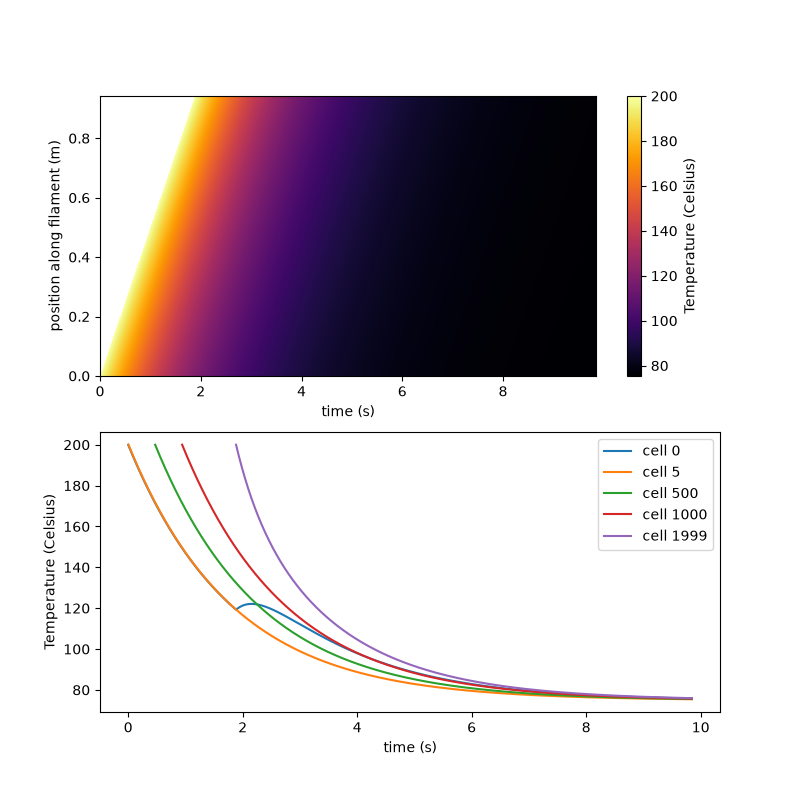

In [17]:
plots_q16(T, num_blocks, dt, dx)

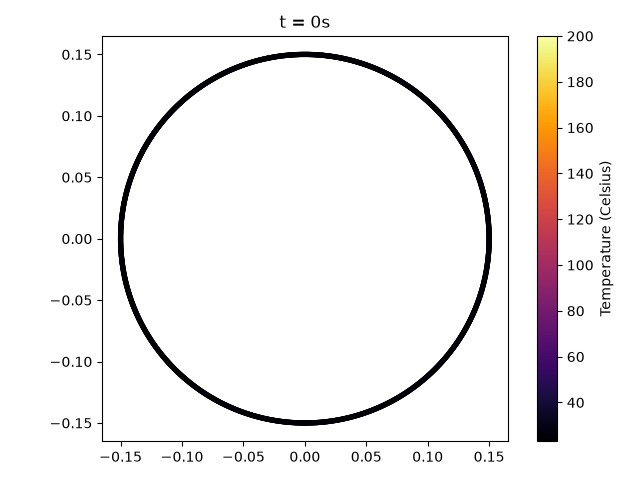

In [11]:
an = plot_q16_over_time(T, num_blocks, num_timesteps, r, dt, p)

### Q2.1) Filament Replacement


### Q2.2) Automaton

### Q3.1) Filament Replacement

# Full System Equations

In [12]:
# Filament usage
# Tweak alpha to have the printer run out faster! :)
def f_fil(x, p):
    return -p.alpha * np.sqrt(x[S.DX]**2 + x[S.DY]**2)

# Printing progress
def f_prog(x, q, p):
    if q.mode == Mode.PRINTING:
        return 1
    else:
        return 0

# This is the equation to put in solve_ivp that will describe
# my system's physical behavior
def sys(x, q: Q, u, p):
    mask = np.ones(6)
    b_mask = 1
    nozzle_mask = 1
    wipe_time = 0
    match q.mode:
        case Mode.MOVING_X0 | Mode.MOVING_XD:
            mask[[S.X, S.DX]] = 0
        case Mode.MOVING_Y0 | Mode.MOVING_YD:
            mask[[S.Y, S.DY]] = 0
        case Mode.SAVING | Mode.HEAT_OFF | Mode.HEAT_ON | Mode.WIPING | Mode.LOADING:
            b_mask = 0
    match q.mode:
        case Mode.HEAT_OFF | Mode.LOADING:
            nozzle_mask = 0
        case _ :
            nozzle_mask = 1
    dx = np.hstack((
        mask * (A @ x[PRINTER] + b_mask * B @ u[U_PRINTER]),
        f_nozzle(x[NOZZLE], nozzle_mask * u[U_NOZZLE]),
        f_fil(x, p),
        f_prog(x, q, p),
        0, 0, 1, 1
    ))
    return dx

In [13]:
# Here I define the curve I want to make and initialize system parameters
# Basically setting up simulation
a = 0.1
b = 0.15
omega = 1.5
delta = np.pi / 2 + 0.1

t_start = 0
t_fin = p.t_fin

y = drawing.lissajous_centered(a, b, omega, delta, t_start, t_fin, p.dx, p.dy)

In [14]:
t, x, q, q_t = simulate_hybrid_system(p, A, B, C, CAAB, CAAA, sys, t_start, t_fin, y)

[array([ 2.99500417e-01, -1.49750125e-02, -2.28622673e-03,  2.00000000e-01,
        1.50000000e-01,  1.36333333e-05,  1.88148877e+00,  1.88148877e+01,
        2.00000000e+02,  5.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00])]


[Q(mode=<Mode.PRINTING: 1>) Q(mode=<Mode.SAVING: 2>)
 Q(mode=<Mode.MOVING: 3>) Q(mode=<Mode.MOVING_X0: 4>)
 Q(mode=<Mode.WIPING: 8>) Q(mode=<Mode.HEAT_OFF: 9>)
 Q(mode=<Mode.LOADING: 10>) Q(mode=<Mode.HEAT_ON: 11>)
 Q(mode=<Mode.MOVING_BACK: 12>) Q(mode=<Mode.PRINTING: 1>)
 Q(mode=<Mode.SAVING: 2>) Q(mode=<Mode.MOVING: 3>)
 Q(mode=<Mode.MOVING_Y0: 6>) Q(mode=<Mode.WIPING: 8>)
 Q(mode=<Mode.HEAT_OFF: 9>) Q(mode=<Mode.LOADING: 10>)
 Q(mode=<Mode.HEAT_ON: 11>) Q(mode=<Mode.MOVING_BACK: 12>)
 Q(mode=<Mode.PRINTING: 1>) Q(mode=<Mode.PRINTING: 1>)]
[  0.           2.           2.5          2.77284199   3.2490187
   3.4490187    6.96884281   7.46884281  10.63124578  13.63124578
  60.57852516  61.07852516  61.25237701  61.49459139  61.69459139
  65.21441549  65.71441549  68.87974804  71.87974804 100.        ]


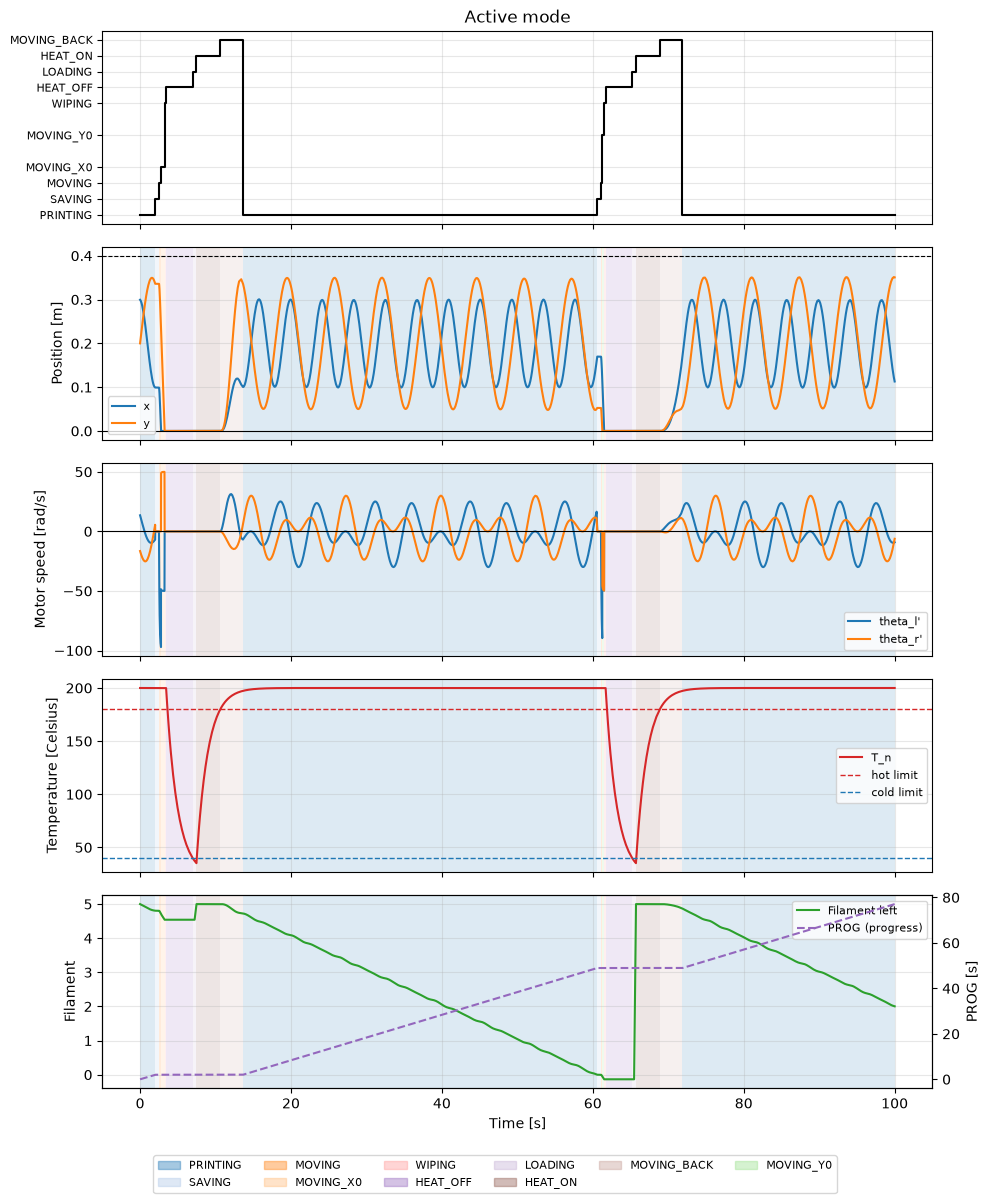

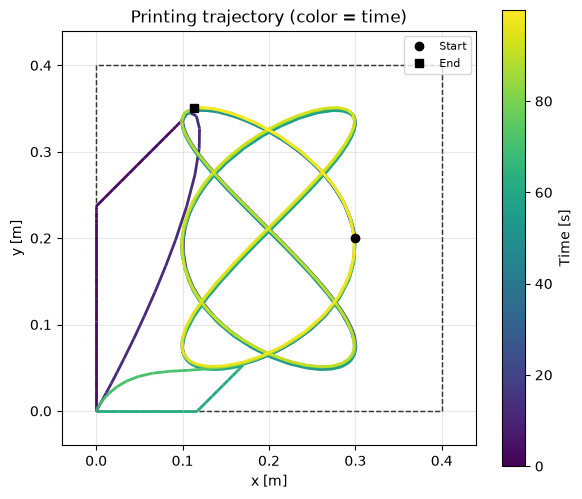

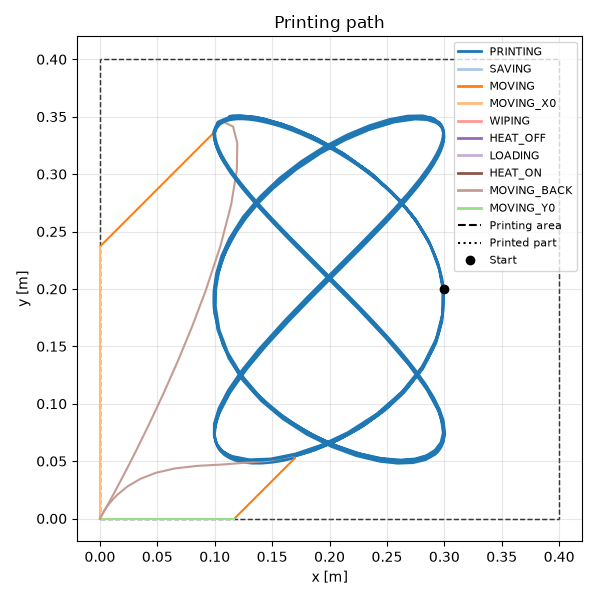

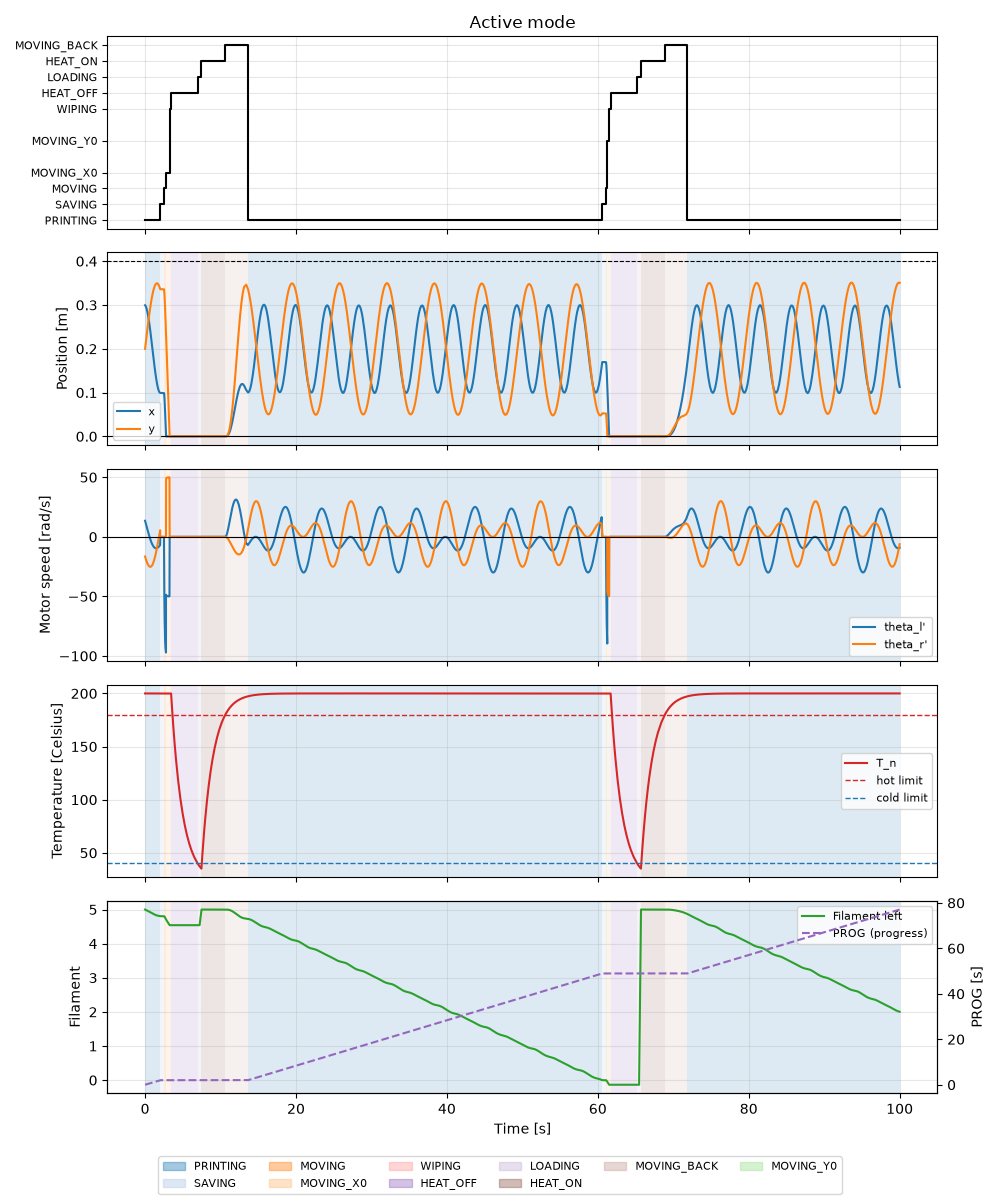

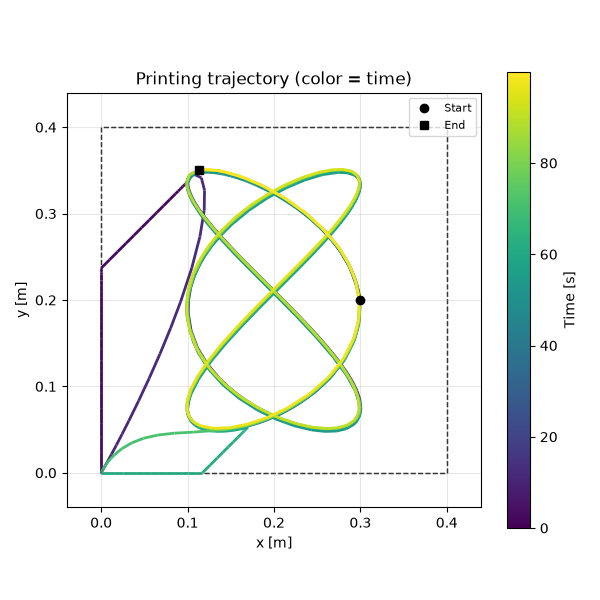

In [15]:
print(q)
print(q_t)

# This plot was made with the help of AI to make it pretty
# It proposed a lot of tweaks and extra tools to visualize things
_, fig_t, fig_path = plot_hybrid(t, x, q, q_t, p)

display(fig_t)

display(fig_path)